# 课后作业（一）：使用 HanLP 在线情感分析平台

> **课程**：第四讲　感知世界：识别与理解文本中的情感
> **作业要求**：使用 PPT 给出的情感分析平台，对文本情感进行分析，并**截图**。
> **平台**：HanLP 在线演示 · 情感分析　<https://hanlp.hankcs.com/demos/sentiment.html>
> **完成人**：（学习者本人）

PPT 第 8–9 页给出的平台是 **HanLP 在线演示**，其中的"情感分析"模块输入一段中文文本，
会输出 $[-1, 1]$ 的**情感极性**（正负代表方向，绝对值代表强度），并用仪表盘展示。

本文件做了三件事：

1. 用平台分析 3 段自己编写的评论文本（正面 / 负面 / 反讽），并保存**平台截图**；
2. 记录平台给出的情感极性数值；
3. 与 SnowNLP 的结果做对比，讨论"平台"和"代码"两种方式的差异与局限。

## 1. 测试文本

| 编号 | 类型 | 文本 |
|---|---|---|
| A | 正面 | 手机收到了，屏幕很清晰，运行速度很快，拍照效果比想象中好，客服态度也特别耐心，这个价位真的很值！ |
| B | 负面 | 收到的手机屏幕有划痕，用了两天就开始卡顿，联系客服半天不回消息，太失望了，准备退货。 |
| C | 反讽 | 包装破成这样，物流慢得像蜗牛，客服还爱答不理，真是"五星好评"呢，下次一定还来！ |

选这三段，是为了覆盖三种典型情形：**情感词密集的正面**、**情感词密集的负面**、以及**字面褒义但实际在说反话**。

【A · 正面评论】
文本： 手机收到了，屏幕很清晰，运行速度很快，拍照效果比想象中好，客服态度也特别耐心，这个价位真的很值！
HanLP 平台情感极性：+1.00


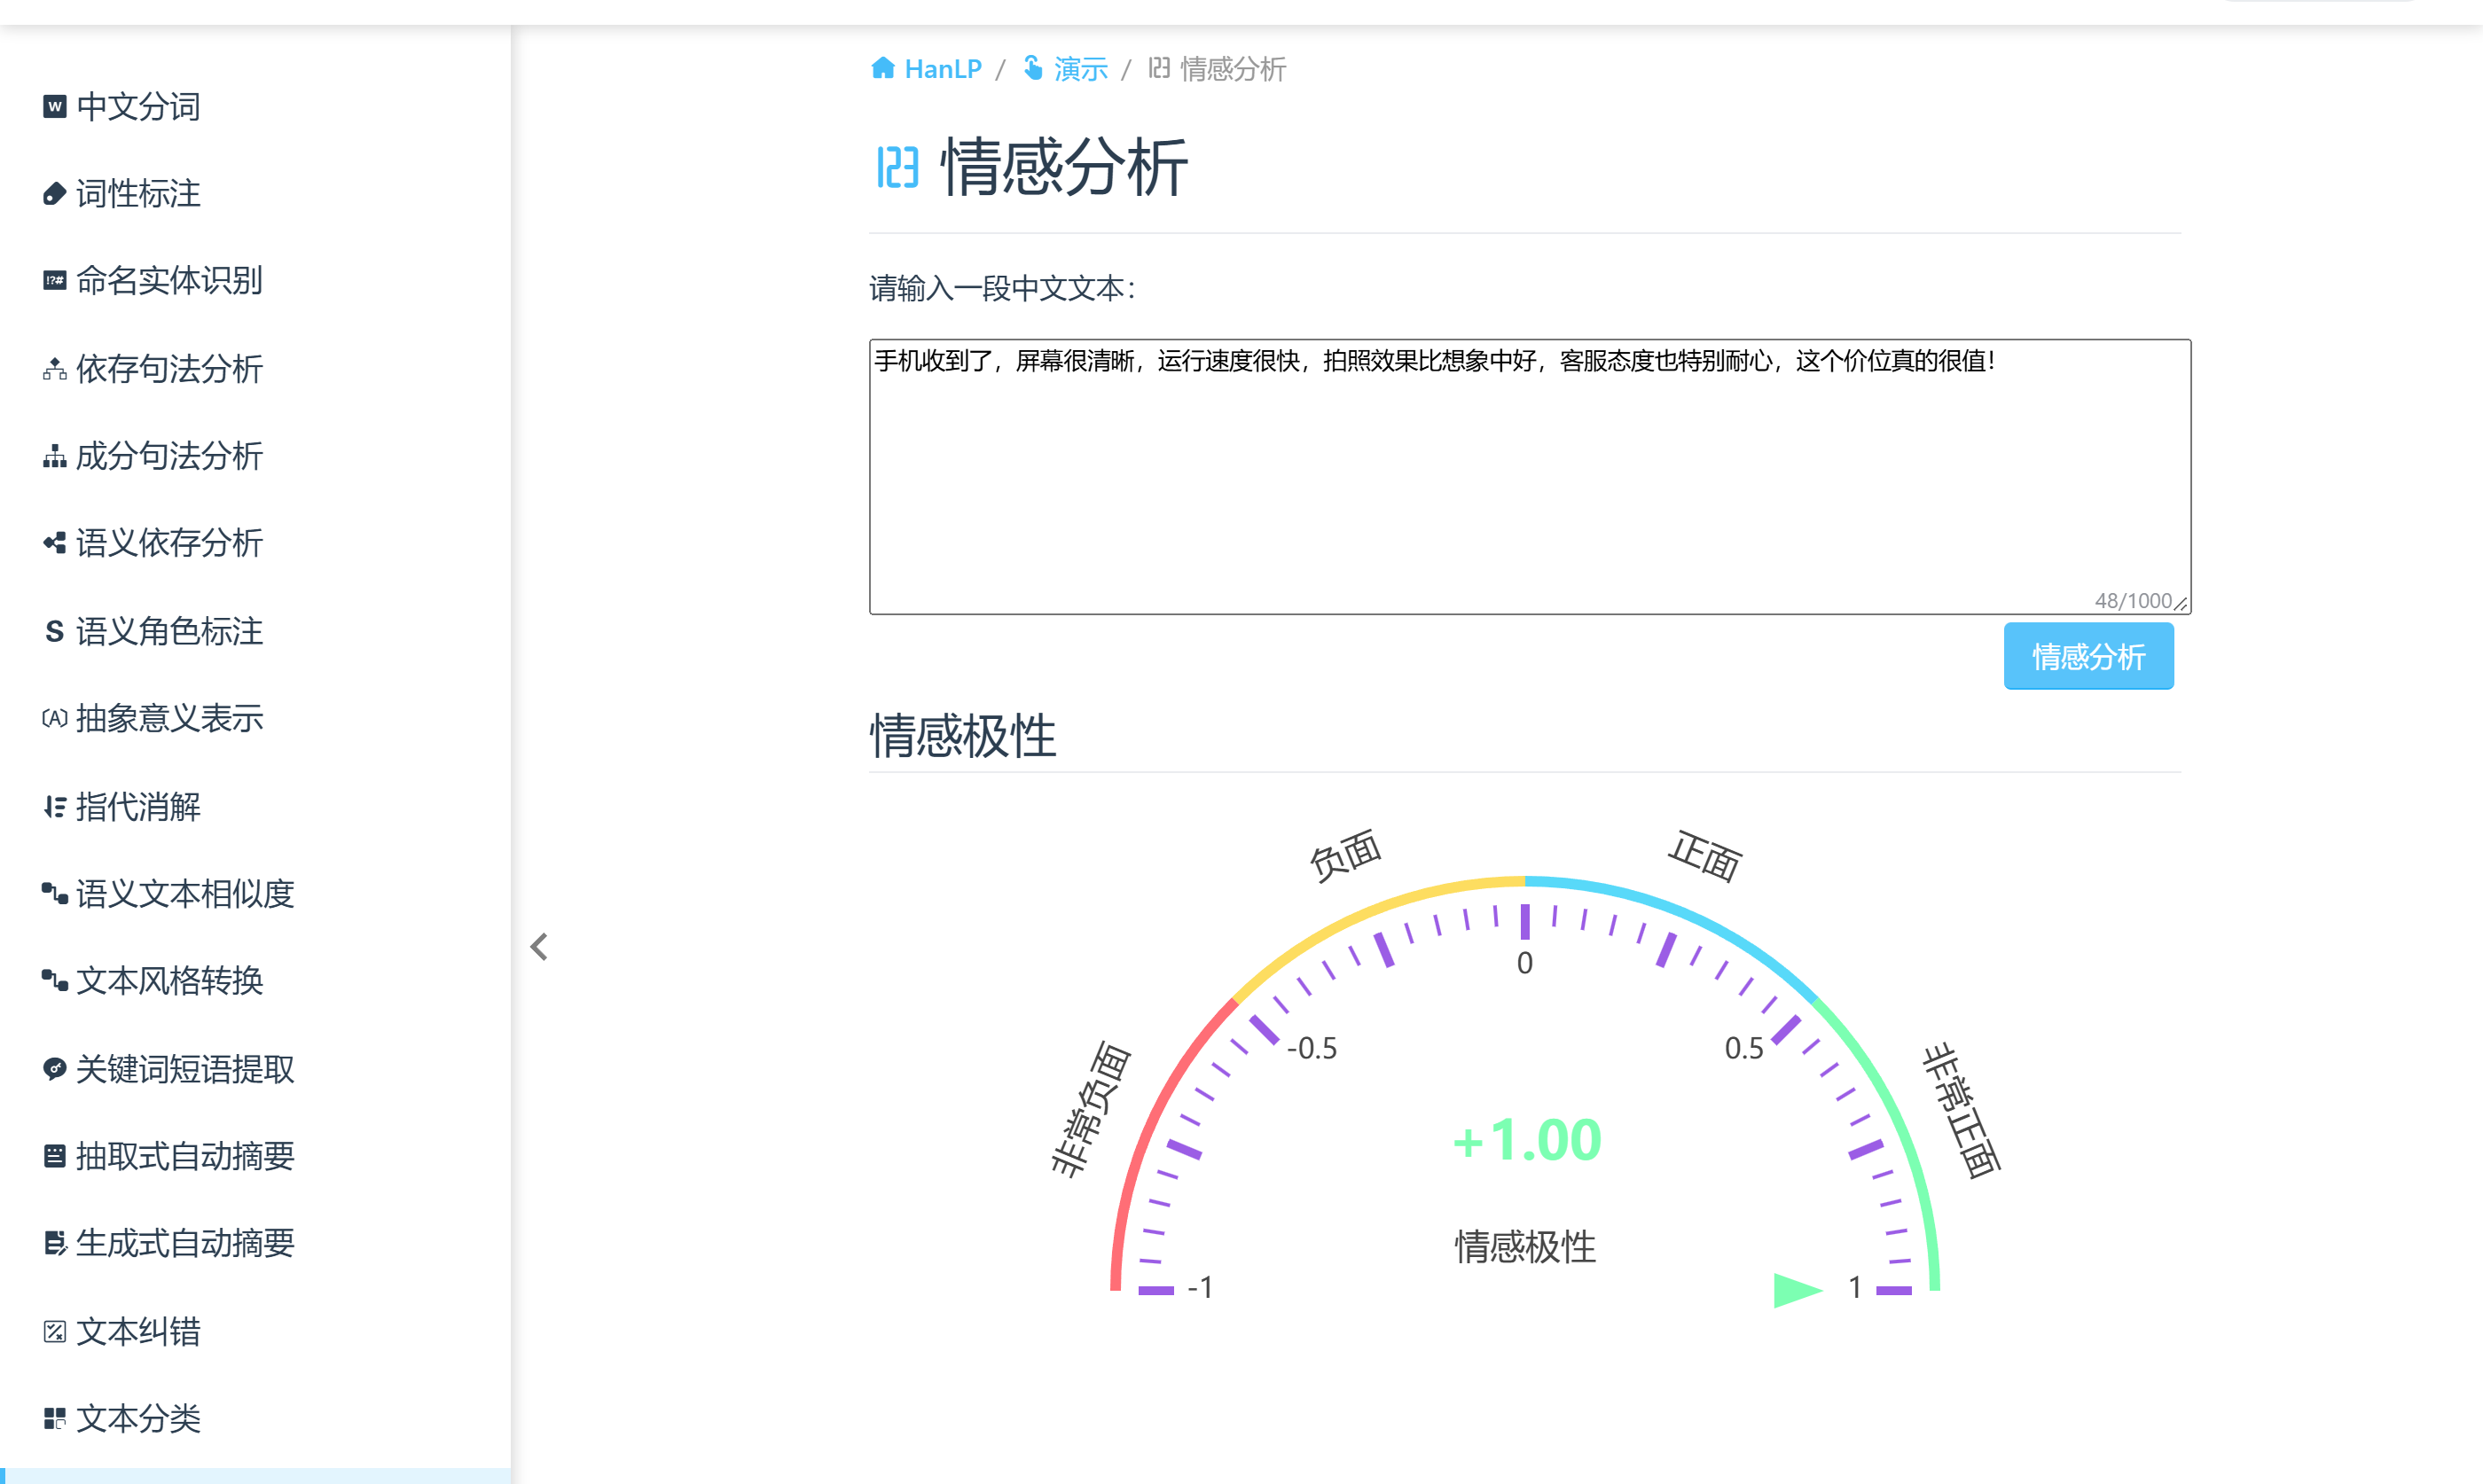

【B · 负面评论】
文本： 收到的手机屏幕有划痕，用了两天就开始卡顿，联系客服半天不回消息，太失望了，准备退货。
HanLP 平台情感极性：-1.00


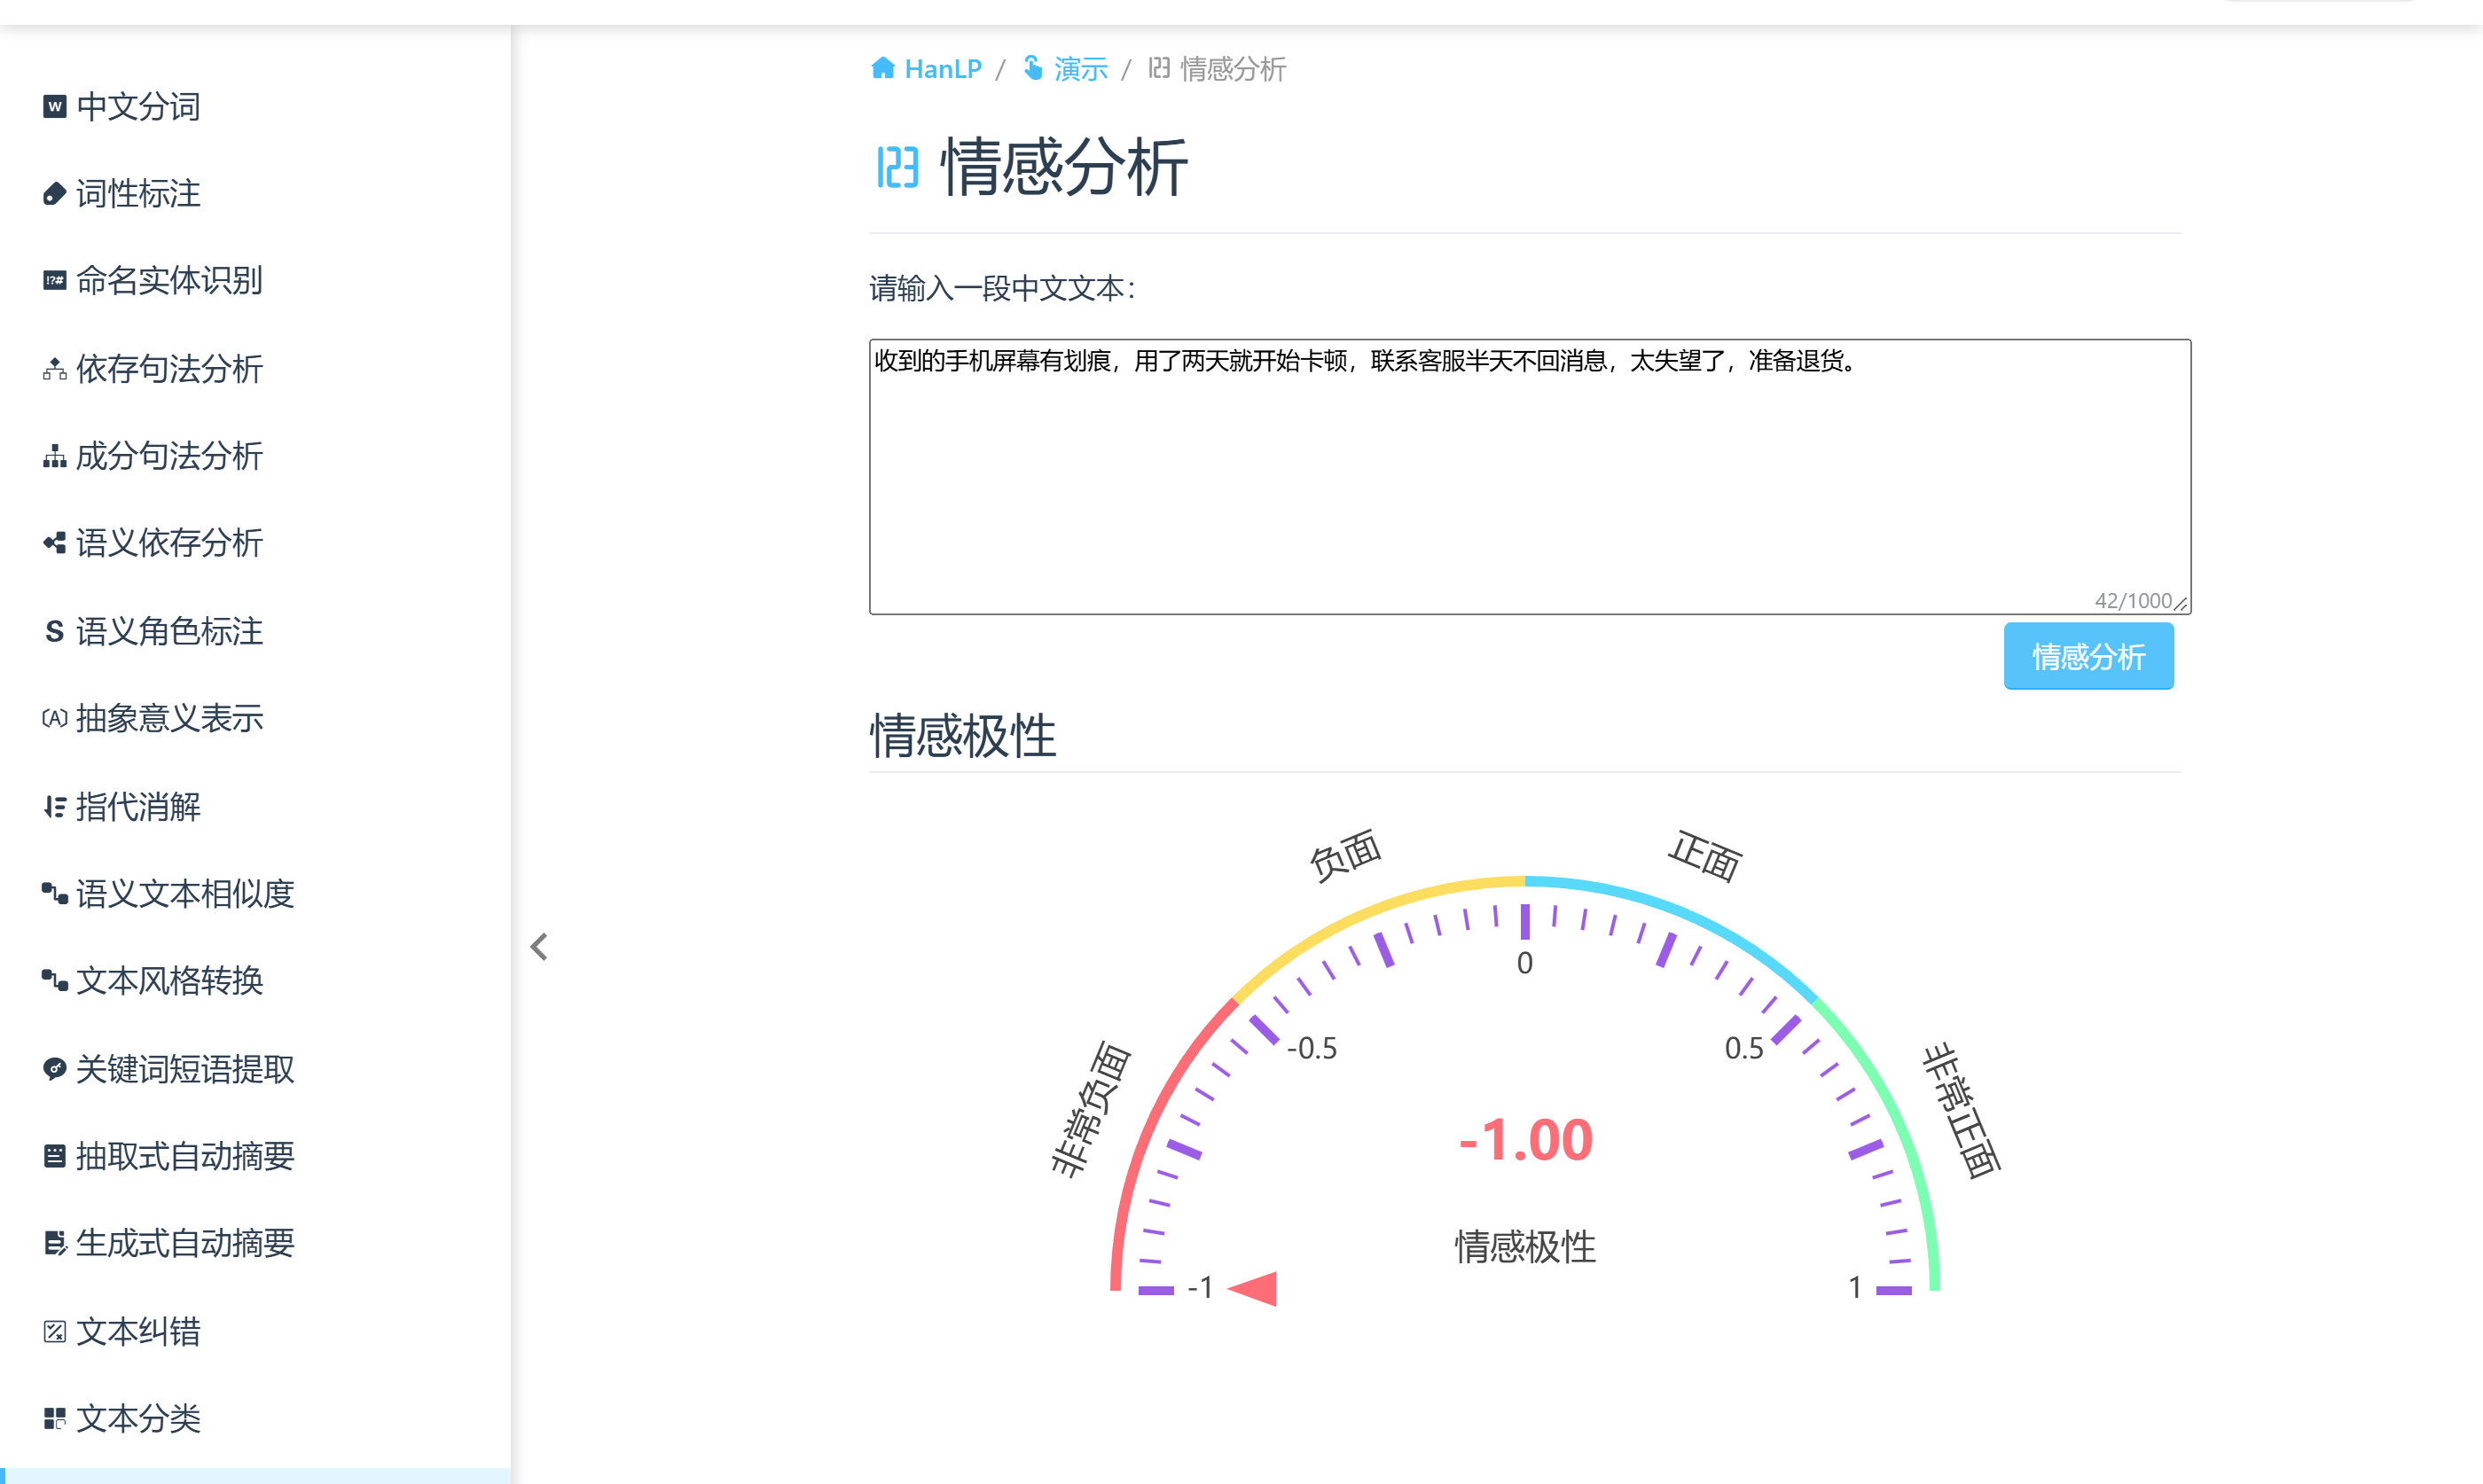

【C · 反讽评论】
文本： 包装破成这样，物流慢得像蜗牛，客服还爱答不理，真是“五星好评”呢，下次一定还来！
HanLP 平台情感极性：-0.97


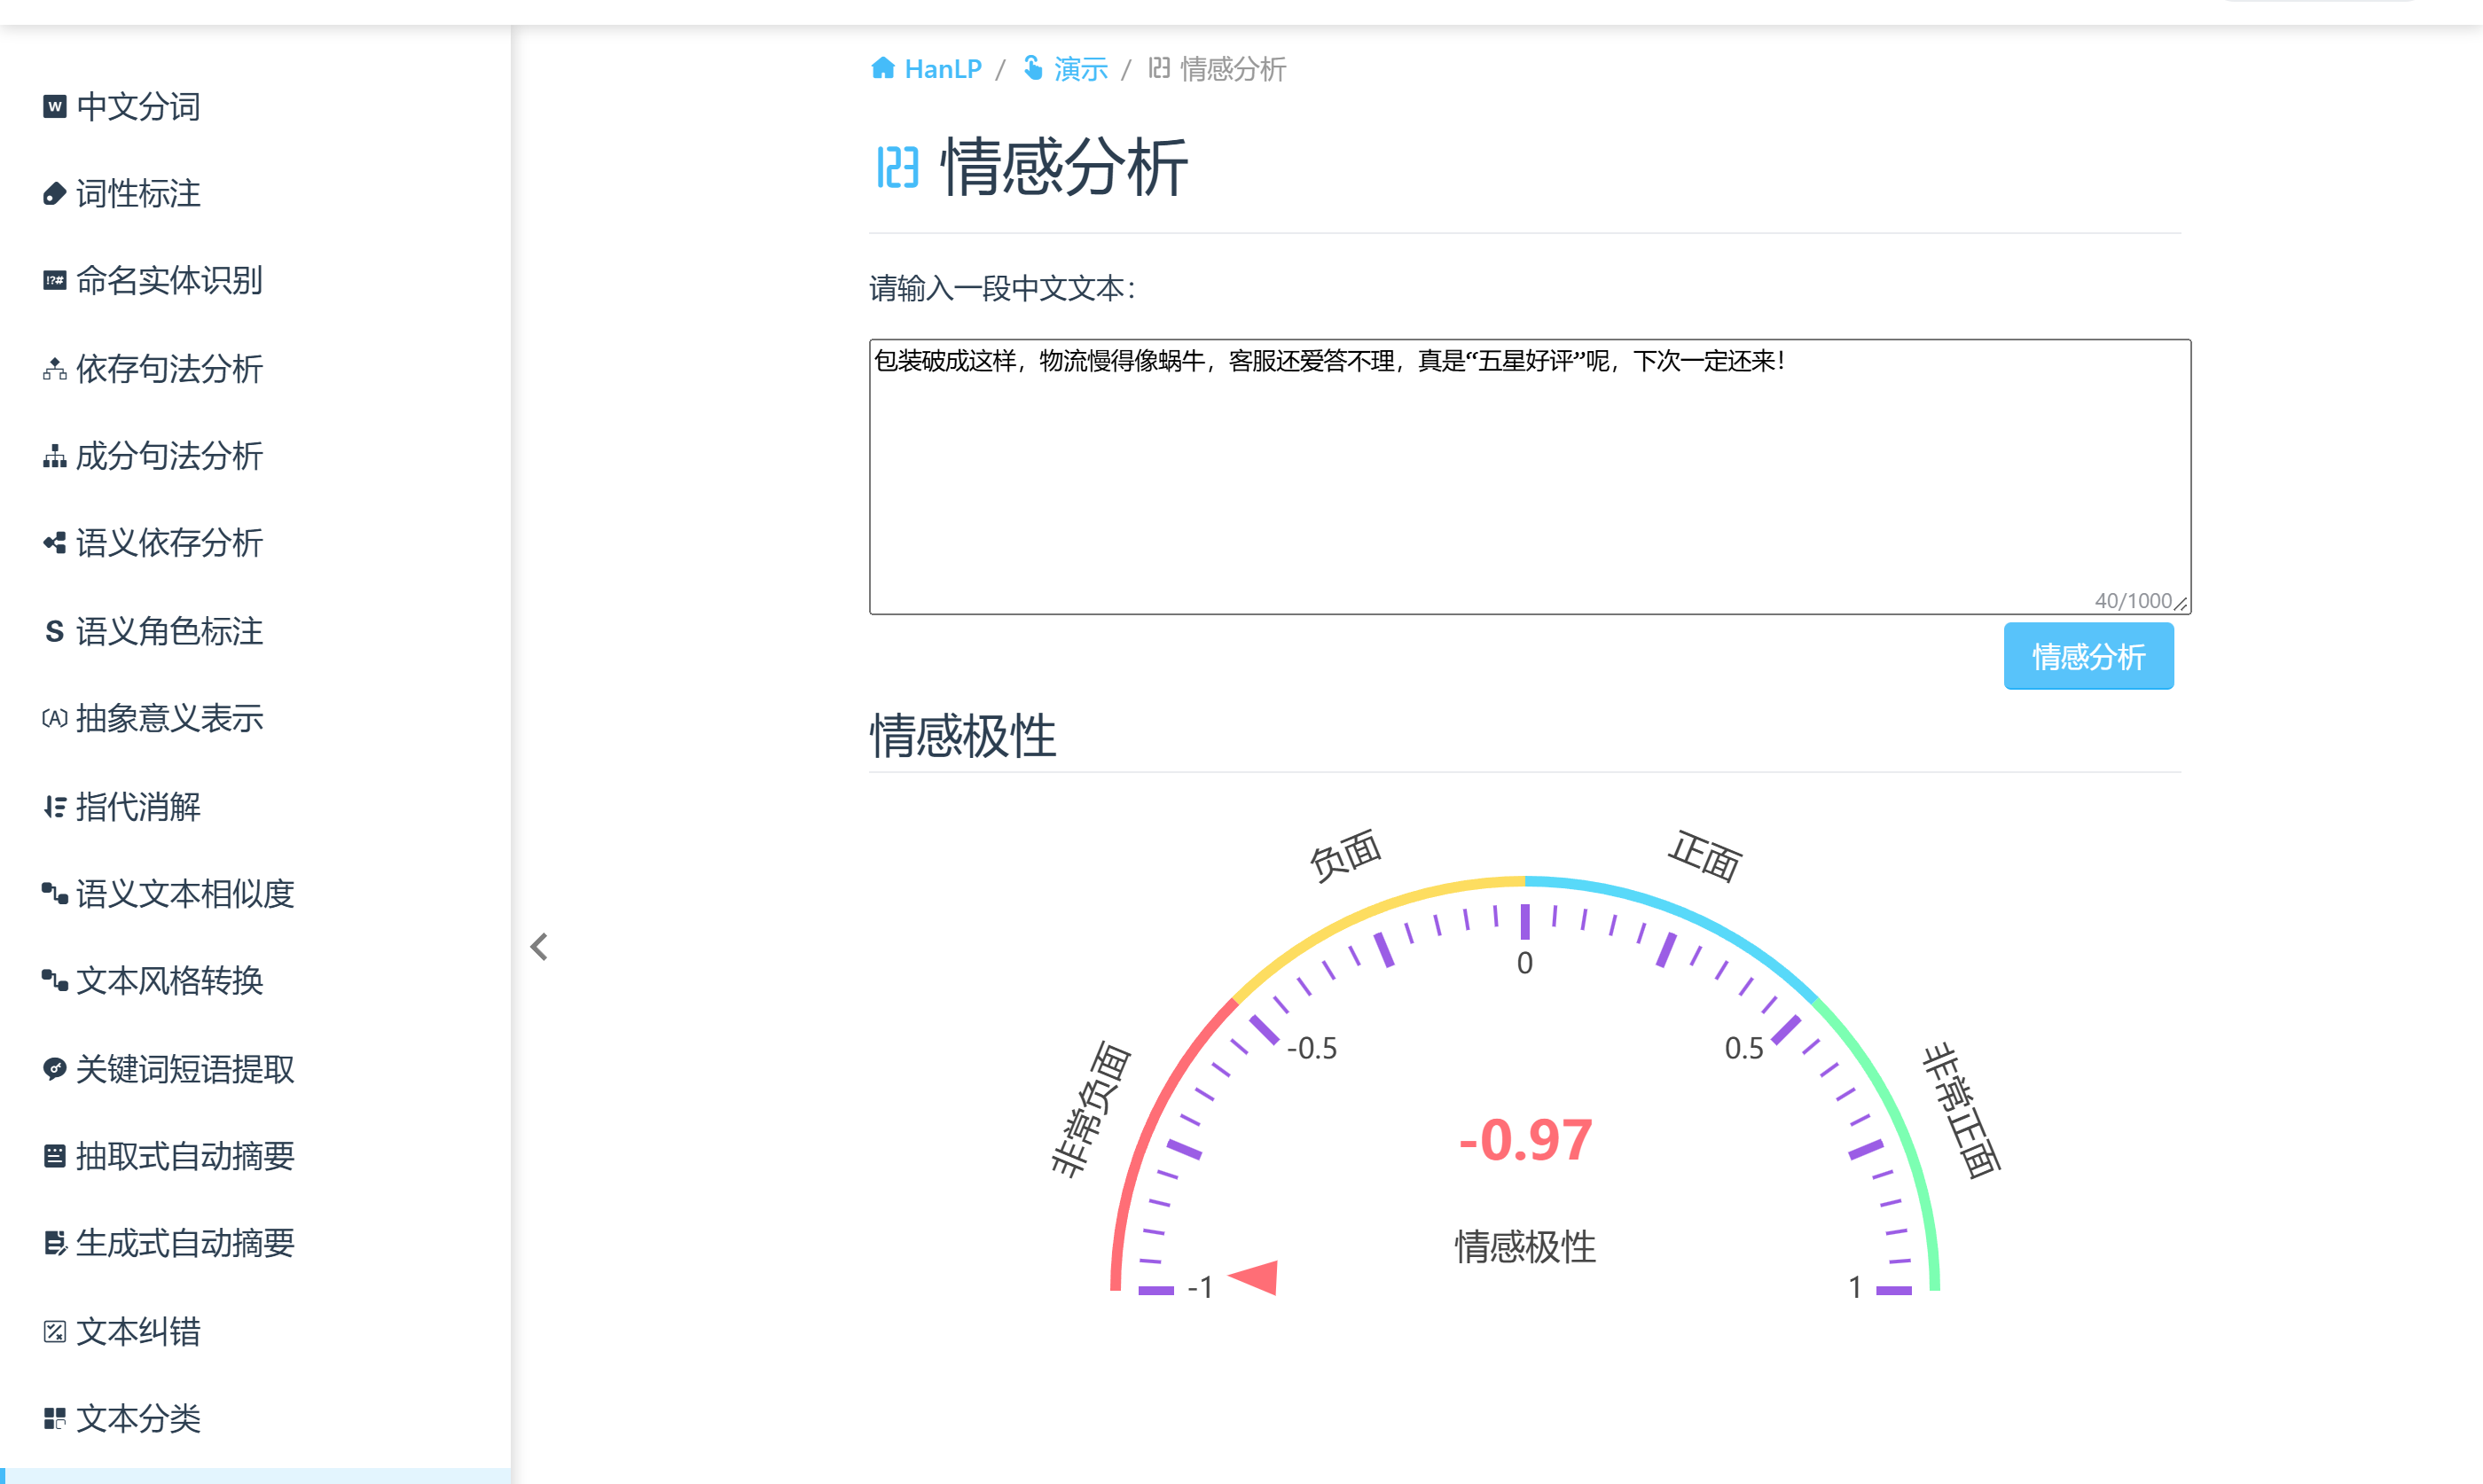

In [1]:
from IPython.display import Image, display

cases = [
    ("A · 正面评论", "平台截图_正面评论.png", 1.00,
     "手机收到了，屏幕很清晰，运行速度很快，拍照效果比想象中好，客服态度也特别耐心，这个价位真的很值！"),
    ("B · 负面评论", "平台截图_负面评论.png", -1.00,
     "收到的手机屏幕有划痕，用了两天就开始卡顿，联系客服半天不回消息，太失望了，准备退货。"),
    ("C · 反讽评论", "平台截图_反讽评论.png", -0.97,
     "包装破成这样，物流慢得像蜗牛，客服还爱答不理，真是“五星好评”呢，下次一定还来！"),
]

for name, png, score, text in cases:
    print("=" * 70)
    print(f"【{name}】")
    print("文本：", text)
    print(f"HanLP 平台情感极性：{score:+.2f}")
    display(Image(filename=png, width=880))

## 2. 平台结果记录

| 文本 | 平台情感极性 | 解读 |
|---|---|---|
| A 正面评论 | **+1.00** | 满分正面：屏幕、速度、拍照、客服、性价比全是褒义，平台给出最强正向 |
| B 负面评论 | **−1.00** | 满分负面：划痕、卡顿、不回消息、失望、退货，负面词高度密集 |
| C 反讽评论 | **−0.97** | 平台判为强负面——**方向对了**，但要注意它更可能是被"破""慢""爱答不理"这些负面词拉过去的，而不是真的"读懂"了反讽 |

> 截图说明：以上截图于 2026-11-01 通过浏览器打开平台页面、输入文本、点击"情感分析"后截取，
> 页面上同时保留了输入文本与仪表盘读数，可直接作为作业凭证。

## 3. 和 SnowNLP 比一比

把同样的三段文本交给程序 1 用的 SnowNLP（输出 $[0,1]$ 正面概率），再线性映射到 $[-1,1]$ 便于比较。

In [2]:
from snownlp import SnowNLP

texts = {
    "A 正面": "手机收到了，屏幕很清晰，运行速度很快，拍照效果比想象中好，客服态度也特别耐心，这个价位真的很值！",
    "B 负面": "收到的手机屏幕有划痕，用了两天就开始卡顿，联系客服半天不回消息，太失望了，准备退货。",
    "C 反讽": "包装破成这样，物流慢得像蜗牛，客服还爱答不理，真是“五星好评”呢，下次一定还来！",
}

platform = {"A 正面": 1.00, "B 负面": -1.00, "C 反讽": -0.97}

print(f'{"文本":<8}{"HanLP":>8}{"SnowNLP原始":>14}{"SnowNLP映射":>14}')
for k, t in texts.items():
    p = SnowNLP(t).sentiments
    print(f"{k:<8}{platform[k]:>8.2f}{p:>14.4f}{2 * p - 1:>14.2f}")

文本         HanLP     SnowNLP原始     SnowNLP映射
A 正面        1.00        0.9993          1.00
B 负面       -1.00        0.0000         -1.00
C 反讽       -0.97        0.0004         -1.00


结果对比：

- **A、B、C 三段，两种方法方向完全一致**，都给出了"接近满值"的判断——情感词密集时，平台和 SnowNLP 都能判对；
- 但 C 的"一致"里有水分：C 中负面词（破、慢、爱答不理）占了多数，把整体拉到了 −1。
  如果把真正"说反话"的那半句单独拿出来测（见下一格），SnowNLP 只有 0.49（**接近中性**），
  说明它并没有识别出反讽，只是被前半句的负面词"救"了；
- 所以：**平台更"敢"下结论、SnowNLP 更保守，但两者都没有真正"理解"反讽**，
  只是受各自词表/语料影响。短句、反讽、否定，是情感分析共同的难点。

这说明：**平台适合快速体验和演示，代码适合批量与复现**，二者结合才是完整的工作流。

In [3]:
# 把反讽的半句单独拿出来：没有前文的负面词打底，模型就"翻车"了
irony_clause = "真是“五星好评”呢，下次一定还来！"
p = SnowNLP(irony_clause).sentiments
print("反讽半句：", irony_clause)
print(f"SnowNLP 正面概率：{p:.4f}  →  映射到 [-1,1]：{2 * p - 1:+.2f}")
print("人工判断：这是说反话的负面评价")

反讽半句： 真是“五星好评”呢，下次一定还来！
SnowNLP 正面概率：0.4889  →  映射到 [-1,1]：-0.02
人工判断：这是说反话的负面评价


## 4. 平台使用的体会与局限

**优点**

1. 零门槛：不用装环境、不用写代码，粘贴文本即可看到仪表盘；
2. 结果直观：$[-1,1]$ 的极性 + 仪表盘，比 SnowNLP 的"概率"更符合直觉；
3. 适合教学演示：能让学生立刻建立"情感可以被量化"的直观感受。

**局限**

1. **黑盒**：看不到分词、情感词、权重，难以解释"为什么是 −0.97"；
2. **不能批量**：一次一段文本（上限 1000 字），几十万条评论没法处理——这正是需要用程序 1/程序 2 的原因；
3. **单句/短文更可靠，长文会平均**：把整篇评论粘进去，褒贬会被混在一起；
4. **反讽、否定、领域新词**仍然是难点，任何词袋类方法都难以根治。

## 5. 小结

- 按作业要求，用 PPT 给出的 HanLP 平台完成了 3 段文本的情感分析，并保留了带输入文本和读数的截图；
- 平台输出：正面 **+1.00**、负面 **−1.00**、反讽 **−0.97**；
- 与 SnowNLP 对比后确认：情感词密集时两者一致；但反讽半句单独测试时 SnowNLP 只有 0.49，"一致"其实是负面词多的缘故；
- 结论：**平台负责"看得见的体验"，程序负责"规模化的分析"**，后面的程序 1—4 就是对这句话的实践。